In [1]:
import yaml
import pandas as pd
import os

In [2]:
def load_yaml(file_name, run_name):
    # name, data_name, loss_name = inputs
    # """Load a YAML file and return its content as a dictionary."""
    # file_name = f"{name}_{data_name}_{loss_name}" if loss_name != 'default' else f"{name}_{data_name}"
    model_info_file = f"{file_name}/{run_name}/model_info.yaml"
    with open(model_info_file, "r") as f:
        return yaml.safe_load(f)

In [3]:
def create_results_table(yaml_paths,  
                         columns= ["Model", "# Params", "Acc.", "AUC g", "AUC q", "AUC W", "AUC Z", "AUC t", "FLOPS"], 
                         compare=None, folds=True):
    
    data_list = []

    for inputs in yaml_paths:
        name, data_name, loss_name, run_name = inputs
        file_name = f"{name}_{data_name}_{loss_name}" if loss_name != 'default' else f"{name}_{data_name}"
        model_info = load_yaml(file_name, run_name)
        
        # Extracting relevant data
        model_name = file_name
        
        if not folds:
            num_const = model_info.get("Model Specifications", {}).get("Number of Parameters", "N/A")
            flops = model_info.get("Model Specifications", {}).get("FLOPs", "N/A")
            acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
            
            auc_scores = model_info.get("AUC Scores", {})
            auc_g = auc_scores.get("Gluon", "N/A")
            auc_q = auc_scores.get("Quark", "N/A")
            auc_w = auc_scores.get("W", "N/A")
            auc_z = auc_scores.get("Z", "N/A")
            auc_t = auc_scores.get("Top", "N/A")
            
        else:
            num_const = int(float(model_info["Model Specifications"]["Number of Parameters"]["Mean"]))
            flops = int(float(model_info["Model Specifications"]["FLOPs"]["Mean"]))    
            
            acc = float(model_info["Validation Performance"]["Test Accuracy"]["Mean"])
            acc_std = float(model_info["Validation Performance"]["Test Accuracy"]["Std"])
            
            auc_scores = model_info["AUC Scores"]
            auc_g = float(auc_scores["Gluon"]["Mean"])
            auc_g_std = float(auc_scores["Gluon"]["Std"])
            
            auc_q = float(auc_scores["Quark"]["Mean"])
            auc_q_std = float(auc_scores["Quark"]["Std"])
            
            auc_w = float(auc_scores["W"]["Mean"])
            auc_w_std = float(auc_scores["W"]["Std"])
            
            auc_z = float(auc_scores["Z"]["Mean"])
            auc_z_std = float(auc_scores["Z"]["Std"])
            
            auc_t = float(auc_scores["Top"]["Mean"])
            auc_t_std = float(auc_scores["Top"]["Std"])
        
        def round_if_number(value):
            return round(value, 4) if isinstance(value, (int, float)) else value
        
        def format_thousands(value):
            if isinstance(value, (int, float)):
                if value >= 1_000_000:
                    return f"{round(value / 1_000_000, 2)}M"
                elif value >= 1_000:
                    return f"{round(value / 1_000, 1)}k"
            return value  # Keep as-is if it's not a number

        # Apply rounding
        num_const = format_thousands(num_const)
        flops = format_thousands(flops)
        acc = round_if_number(acc)*100
        auc_g = round_if_number(auc_g)*100
        auc_q = round_if_number(auc_q)*100
        auc_w = round_if_number(auc_w)*100
        auc_z = round_if_number(auc_z)*100
        auc_t = round_if_number(auc_t)*100
        
        if folds:
            acc_std = round_if_number(acc_std)*100
            auc_g_std = round_if_number(auc_g_std)*100
            auc_q_std = round_if_number(auc_q_std)*100
            auc_w_std = round_if_number(auc_w_std)*100
            auc_z_std = round_if_number(auc_z_std)*100
            auc_t_std = round_if_number(auc_t_std)*100
            
            acc = f"{acc:.2f} ± {acc_std:.2f}"
            auc_g = f"{auc_g:.2f} ± {auc_g_std:.2f}"
            auc_q = f"{auc_q:.2f} ± {auc_q_std:.2f}"    
            auc_w = f"{auc_w:.2f} ± {auc_w_std:.2f}"
            auc_z = f"{auc_z:.2f} ± {auc_z_std:.2f}"
            auc_t = f"{auc_t:.2f} ± {auc_t_std:.2f}"

        # Append row to the table
        if columns == ["Model", "# Params", "Acc.", "AUC g", "AUC q", "AUC W", "AUC Z", "AUC t", "FLOPS"]:
            data_list.append([model_name, num_const, acc, auc_g, auc_q, auc_w, auc_z, auc_t, flops])
        elif columns == ["Model", "Acc."]:
            data_list.append([model_name, acc])
                
    # Create DataFrame
    
    if compare == None: 
        df = pd.DataFrame(data_list, columns=columns)
    else:
        # Create the main DataFrame from data_list
        df = pd.DataFrame(data_list, columns=columns)
        
        # Create the reference DataFrame from compare (without "Model")
        ref_df = pd.DataFrame(compare, columns=columns[1:])  # Exclude "Model" column
        
        # Align the reference DataFrame with the main DataFrame
        ref_df.index = df.index  # Ensure the indices match
        
        # Add the reference columns to the main DataFrame with a suffix
        df = pd.concat([df, ref_df.add_suffix(" Ref")], axis=1)

    df.reset_index(drop=True, inplace=True)  # Reset the index for a clean DataFrame

    return df

In [4]:
new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot_folds'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

yaml_paths = [('deepset', 'pt_etarel_phirel_8', 'default'), 
              ('deepset', 'pt_etarel_phirel_16', 'default'),
              ('deepset', 'pt_etarel_phirel_32', 'default'), 
              ('deepset', 'px_py_pz_etarel_phirel_8', 'so3_eta_phi'),
              ('deepset', 'px_py_pz_etarel_phirel_16', 'so3_eta_phi'), 
              ('deepset', 'px_py_pz_etarel_phirel_32', 'so3_eta_phi'),
              ('deepset', 'px_py_pz_etarel_phirel_data_aug_8', 'default'),
              ('deepset', 'px_py_pz_etarel_phirel_data_aug_16', 'default'),
              ('deepset', 'px_py_pz_etarel_phirel_data_aug_32', 'default'), 
              ('transformer', 'pt_etarel_phirel_8', 'default'),
              ('transformer', 'pt_etarel_phirel_16', 'default'), 
              ('transformer', 'pt_etarel_phirel_32', 'default'),
              ('transformer', 'px_py_pz_etarel_phirel_8', 'so3_eta_phi'),
              ('transformer', 'px_py_pz_etarel_phirel_16', 'so3_eta_phi'),
              ('transformer', 'px_py_pz_etarel_phirel_32', 'so3_eta_phi'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_8', 'default'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_16', 'default'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_32', 'default')
              ]

compare = ["63.4 ± 0.1", "71.7 ± 0.1", "77.4 ± 0.1", "64.9 ± 0.4", "71.6 ± 0.2", "78.6 ± 0.1", 
            "65.6 ± 0.3", "71.6 ± 0.2", "78.6 ± 0.1", "66.4 ± 0.4", "73.1 ± 0.2", "79.0 ± 0.1",
            "65.9", "73.0 ± 0.1", "77.3 ± 0.2", "67.0 ± 0.1", "74.8 ± 0.2", "79.9 ± 0.1"]

create_results_table(yaml_paths, "run_1", columns=["Model","Acc."], compare=compare, folds=True)

✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot_folds


TypeError: create_results_table() got multiple values for argument 'columns'

In [7]:
new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

yaml_paths = [('deepset', 'pt_etarel_phirel_8', 'default', 'custom_minmax'), 
              ('deepset', 'pt_etarel_phirel_16', 'default', 'custom_minmax'),
              ('deepset', 'pt_etarel_phirel_32', 'default', 'custom_minmax'), 
              ('deepset', 'px_py_pz_etarel_phirel_8', 'so3_eta_phi', 'custom_minmax'),
              ('deepset', 'px_py_pz_etarel_phirel_16', 'so3_eta_phi', 'custom_minmax'), 
              ('deepset', 'px_py_pz_etarel_phirel_32', 'so3_eta_phi', 'custom_minmax'),
              ('deepset', 'px_py_pz_etarel_phirel_data_aug_8', 'default', 'custom_minmax'),
              ('deepset', 'px_py_pz_etarel_phirel_data_aug_16', 'default', 'custom_minmax'),
              ('deepset', 'px_py_pz_etarel_phirel_data_aug_32', 'default', 'custom_minmax'), 
              ('transformer', 'pt_etarel_phirel_8', 'default', 'custom_minmax_no_mask_fill'),
              ('transformer', 'pt_etarel_phirel_16', 'default', 'custom_minmax_no_mask_fill'), 
              ('transformer', 'pt_etarel_phirel_32', 'default', 'custom_minmax_no_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_8', 'so3_eta_phi', 'custom_minmax_no_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_16', 'so3_eta_phi', 'custom_minmax_no_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_32', 'so3_eta_phi', 'custom_minmax_no_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_8', 'default', 'custom_minmax_no_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_16', 'default', 'custom_minmax_no_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_32', 'default', 'custom_minmax_no_mask_fill'),
              ('transformer', 'pt_etarel_phirel_8', 'default', 'custom_minmax_with_mask_fill'),
              ('transformer', 'pt_etarel_phirel_16', 'default', 'custom_minmax_with_mask_fill'), 
              ('transformer', 'pt_etarel_phirel_32', 'default', 'custom_minmax_with_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_8', 'so3_eta_phi', 'custom_minmax_with_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_16', 'so3_eta_phi', 'custom_minmax_with_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_32', 'so3_eta_phi', 'custom_minmax_with_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_8', 'default', 'custom_minmax_with_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_16', 'default', 'custom_minmax_with_mask_fill'),
              ('transformer', 'px_py_pz_etarel_phirel_data_aug_32', 'default', 'custom_minmax_with_mask_fill')
              ]

compare = ["63.4 ± 0.1", "71.7 ± 0.1", "77.4 ± 0.1", "64.9 ± 0.4", "71.6 ± 0.2", "78.6 ± 0.1", 
            "65.6 ± 0.3", "71.6 ± 0.2", "78.6 ± 0.1", "66.4 ± 0.4", "73.1 ± 0.2", "79.0 ± 0.1",
            "65.9", "73.0 ± 0.1", "77.3 ± 0.2", "67.0 ± 0.1", "74.8 ± 0.2", "79.9 ± 0.1", 
            "66.4 ± 0.4", "73.1 ± 0.2", "79.0 ± 0.1", "65.9", "73.0 ± 0.1", "77.3 ± 0.2", 
            "67.0 ± 0.1", "74.8 ± 0.2", "79.9 ± 0.1"]

create_results_table(yaml_paths, columns=["Model","Acc."], compare=compare, folds=False)

✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


,Model,Acc.,Acc. Ref
0,deepset_pt_etarel_phirel_8,63.32,63.4 ± 0.1
1,deepset_pt_etarel_phirel_16,70.59,71.7 ± 0.1
2,deepset_pt_etarel_phirel_32,78.20,77.4 ± 0.1
3,deepset_px_py_pz_etarel_phirel_8_so3_eta_phi,63.61,64.9 ± 0.4
4,deepset_px_py_pz_etarel_phirel_16_so3_eta_phi,70.30,71.6 ± 0.2
5,deepset_px_py_pz_etarel_phirel_32_so3_eta_phi,76.53,78.6 ± 0.1
6,deepset_px_py_pz_etarel_phirel_data_aug_8,62.60,65.6 ± 0.3
7,deepset_px_py_pz_etarel_phirel_data_aug_16,68.06,71.6 ± 0.2
8,deepset_px_py_pz_etarel_phirel_data_aug_32,73.73,78.6 ± 0.1
9,transformer_pt_etarel_phirel_8,65.27,66.4 ± 0.4


✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


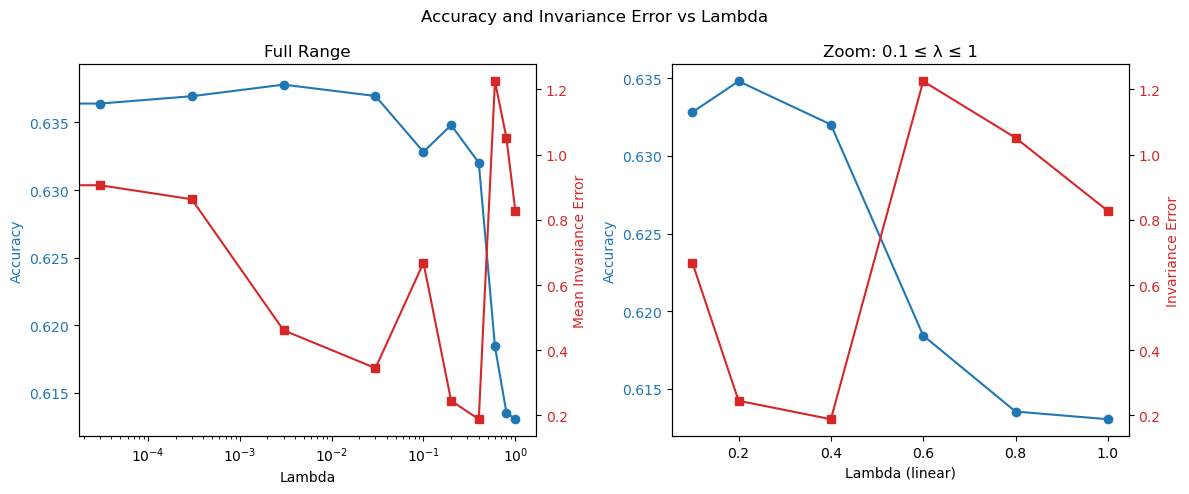

In [5]:
import numpy as np 
import matplotlib.pyplot as plt

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

model = "deepset_px_py_pz_etarel_phirel_8_so2_eta_phi/lam_scan_so2"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
accs = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    # Extracting relevant data
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc)
    
    inv_error = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv_error)
    
lambda_list = np.array(lambda_list)
accs = np.array(accs)
inv_errors = np.array(inv_errors)

mask_zoom = (lambda_list >= 0.1) & (lambda_list <= 1)
lambda_zoom = lambda_list[mask_zoom]
accs_zoom = accs[mask_zoom]
inv_zoom = inv_errors[mask_zoom]

# Create horizontal subplots
fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# --- Main plot (log scale) ---
ax_main.set_title('Full Range')
ax_main.set_xlabel('Lambda')
ax_main.set_ylabel('Accuracy', color='tab:blue')
ax_main.plot(lambda_list, accs, marker='o', color='tab:blue')
ax_main.tick_params(axis='y', labelcolor='tab:blue')
ax_main.set_xscale('log')

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red')
ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red')
ax2_main.tick_params(axis='y', labelcolor='tab:red')

# --- Zoomed plot (linear scale) ---
ax_zoom.set_title('Zoom: 0.1 ≤ λ ≤ 1')
ax_zoom.set_xlabel('Lambda (linear)')
ax_zoom.set_ylabel('Accuracy', color='tab:blue')
ax_zoom.plot(lambda_zoom, accs_zoom, marker='o', color='tab:blue')
ax_zoom.tick_params(axis='y', labelcolor='tab:blue')

ax2_zoom = ax_zoom.twinx()
ax2_zoom.set_ylabel('Invariance Error', color='tab:red')
ax2_zoom.plot(lambda_zoom, inv_zoom, marker='s', color='tab:red')
ax2_zoom.tick_params(axis='y', labelcolor='tab:red')

fig.suptitle('Accuracy and Invariance Error vs Lambda')
fig.tight_layout()
plt.show()

✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


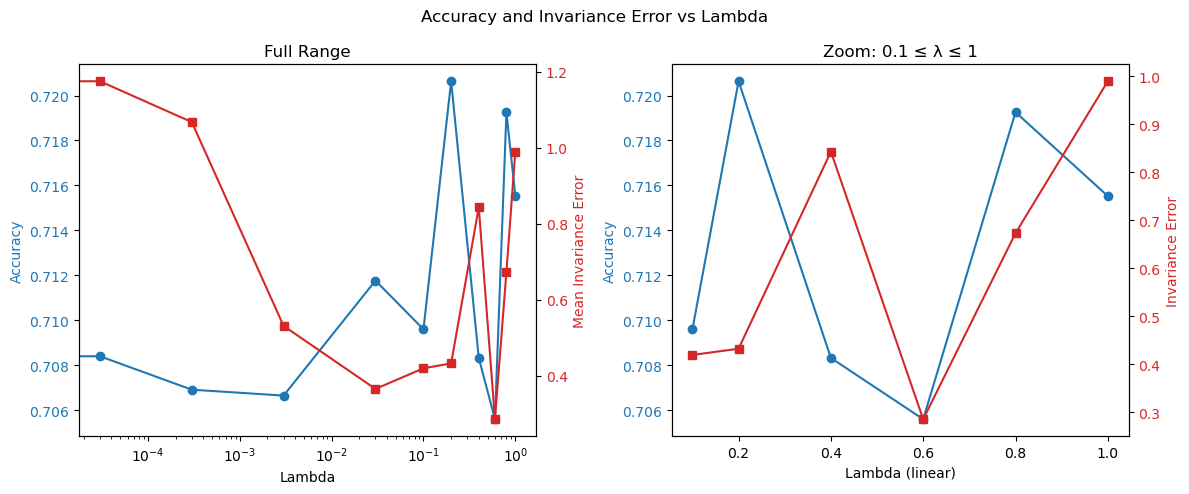

In [6]:
import numpy as np 
import matplotlib.pyplot as plt

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

model = "deepset_px_py_pz_etarel_phirel_16_so2_eta_phi/lam_scan_so2"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
accs = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    # Extracting relevant data
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc)
    
    inv_error = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv_error)
    
lambda_list = np.array(lambda_list)
accs = np.array(accs)
inv_errors = np.array(inv_errors)

mask_zoom = (lambda_list >= 0.1) & (lambda_list <= 1)
lambda_zoom = lambda_list[mask_zoom]
accs_zoom = accs[mask_zoom]
inv_zoom = inv_errors[mask_zoom]

# Create horizontal subplots
fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# --- Main plot (log scale) ---
ax_main.set_title('Full Range')
ax_main.set_xlabel('Lambda')
ax_main.set_ylabel('Accuracy', color='tab:blue')
ax_main.plot(lambda_list, accs, marker='o', color='tab:blue')
ax_main.tick_params(axis='y', labelcolor='tab:blue')
ax_main.set_xscale('log')

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red')
ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red')
ax2_main.tick_params(axis='y', labelcolor='tab:red')

# --- Zoomed plot (linear scale) ---
ax_zoom.set_title('Zoom: 0.1 ≤ λ ≤ 1')
ax_zoom.set_xlabel('Lambda (linear)')
ax_zoom.set_ylabel('Accuracy', color='tab:blue')
ax_zoom.plot(lambda_zoom, accs_zoom, marker='o', color='tab:blue')
ax_zoom.tick_params(axis='y', labelcolor='tab:blue')

ax2_zoom = ax_zoom.twinx()
ax2_zoom.set_ylabel('Invariance Error', color='tab:red')
ax2_zoom.plot(lambda_zoom, inv_zoom, marker='s', color='tab:red')
ax2_zoom.tick_params(axis='y', labelcolor='tab:red')

fig.suptitle('Accuracy and Invariance Error vs Lambda')
fig.tight_layout()
plt.show()

✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


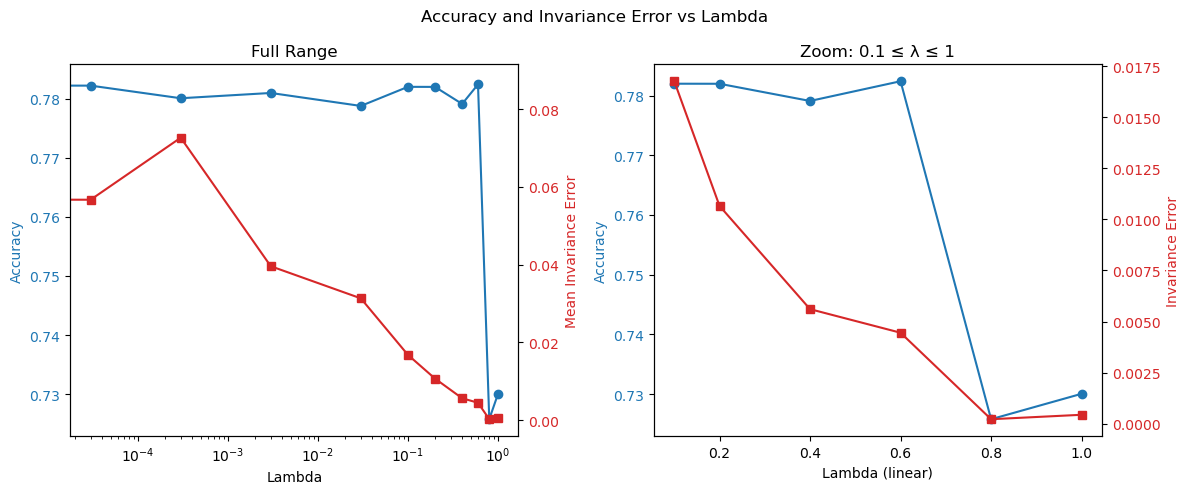

In [11]:
import numpy as np 
import matplotlib.pyplot as plt

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

model = "deepset_px_py_pz_etarel_phirel_32_so2_eta_phi/lam_scan_so2"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
accs = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    # Extracting relevant data
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc)
    
    inv_error = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv_error)
    
lambda_list = np.array(lambda_list)
accs = np.array(accs)
inv_errors = np.array(inv_errors)

mask_zoom = (lambda_list >= 0.1) & (lambda_list <= 1)
lambda_zoom = lambda_list[mask_zoom]
accs_zoom = accs[mask_zoom]
inv_zoom = inv_errors[mask_zoom]

# Create horizontal subplots
fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# --- Main plot (log scale) ---
ax_main.set_title('Full Range')
ax_main.set_xlabel('Lambda')
ax_main.set_ylabel('Accuracy', color='tab:blue')
ax_main.plot(lambda_list, accs, marker='o', color='tab:blue')
ax_main.tick_params(axis='y', labelcolor='tab:blue')
ax_main.set_xscale('log')

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red')
ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red')
ax2_main.tick_params(axis='y', labelcolor='tab:red')

# --- Zoomed plot (linear scale) ---
ax_zoom.set_title('Zoom: 0.1 ≤ λ ≤ 1')
ax_zoom.set_xlabel('Lambda (linear)')
ax_zoom.set_ylabel('Accuracy', color='tab:blue')
ax_zoom.plot(lambda_zoom, accs_zoom, marker='o', color='tab:blue')
ax_zoom.tick_params(axis='y', labelcolor='tab:blue')

ax2_zoom = ax_zoom.twinx()
ax2_zoom.set_ylabel('Invariance Error', color='tab:red')
ax2_zoom.plot(lambda_zoom, inv_zoom, marker='s', color='tab:red')
ax2_zoom.tick_params(axis='y', labelcolor='tab:red')

fig.suptitle('Accuracy and Invariance Error vs Lambda')
fig.tight_layout()
plt.show()

✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl


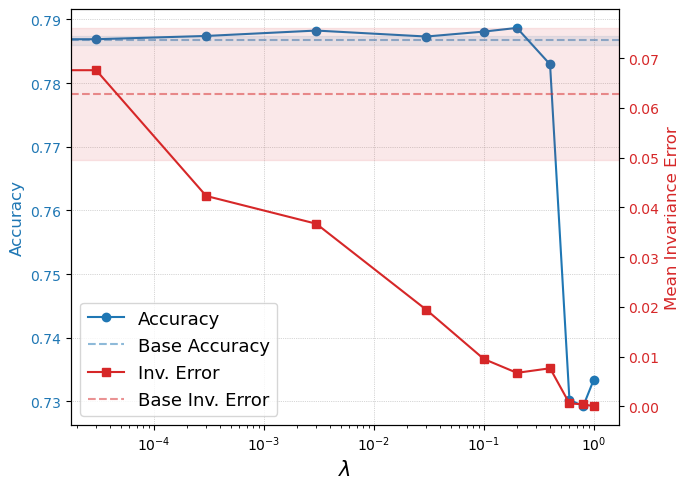

In [11]:
import numpy as np 
import matplotlib.pyplot as plt
import os
import yaml

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl'
os.chdir(new_directory)
print("✅ Current Working Directory:", os.getcwd())

model = "plot/deepset_px_py_pz_etarel_phirel_32_so2_eta_phi/lam_scan_so2_compare_to_output_2"
base_model = "plot_folds/deepset_px_py_pz_etarel_phirel_32/folds_report"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
inv_std = []
accs = []
acc_std = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc if isinstance(acc, float) else np.nan)

    acc_s = model_info.get("Validation Performance", {}).get("Test Accuracy Std", 0)
    acc_std.append(acc_s if isinstance(acc_s, float) else 0)

    inv = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv if isinstance(inv, float) else np.nan)

    inv_s = model_info.get("Invariance Properties", {}).get("Mean Invariance Error Std", 0)
    inv_std.append(inv_s if isinstance(inv_s, float) else 0)

lambda_list = np.array(lambda_list)
accs = np.array(accs)
acc_std = np.array(acc_std)
inv_errors = np.array(inv_errors)
inv_std = np.array(inv_std)

with open(f"{base_model}/model_info.yaml", "r") as f:
    base_model_info = yaml.safe_load(f)

base_acc_mean = float(base_model_info["Validation Performance"]["Test Accuracy"]["Mean"])
base_acc_std = float(base_model_info["Validation Performance"]["Test Accuracy"]["Std"])
base_inv_error_mean = float(base_model_info["Invariance Properties"]["Mean Invariance Error"]["Mean"])
base_inv_error_std = float(base_model_info["Invariance Properties"]["Mean Invariance Error"]["Std"])


fig, ax_main = plt.subplots(figsize=(7, 5))

#ax_main.set_title('Accuracy and Invariance Error vs Lambda')
ax_main.set_xlabel(r'$\lambda$', fontsize=15)
ax_main.set_ylabel('Accuracy', color='tab:blue', fontsize=12)

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red', fontsize=12)

ax_main.set_xscale('log')

# Accuracy line and fill
line_acc, = ax_main.plot(lambda_list, accs, marker='o', color='tab:blue', label='Accuracy')

# Base accuracy shaded band
line_base_acc = ax_main.axhline(y=base_acc_mean, linestyle='--', color='tab:blue', alpha=0.5, label='Base Accuracy')
ax_main.axhspan(base_acc_mean - base_acc_std, base_acc_mean + base_acc_std, color='tab:blue', alpha=0.1)

ax_main.tick_params(axis='y', labelcolor='tab:blue')

# Invariance error line and fill
line_inv, = ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red', label='Inv. Error')

# Base inv error shaded band
line_base_inv = ax2_main.axhline(y=base_inv_error_mean, linestyle='--', color='tab:red', alpha=0.5, label='Base Inv. Error')
ax2_main.axhspan(base_inv_error_mean - base_inv_error_std, base_inv_error_mean + base_inv_error_std, color='tab:red', alpha=0.1)

ax2_main.tick_params(axis='y', labelcolor='tab:red')

# Combine legends
lines = [line_acc, line_base_acc, line_inv, line_base_inv]
labels = [line.get_label() for line in lines]
ax_main.legend(lines, labels, loc='lower left', frameon=True, fontsize=13)

ax_main.grid(True, linestyle=':', linewidth=0.5)
fig.tight_layout()
plt.show()


✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl


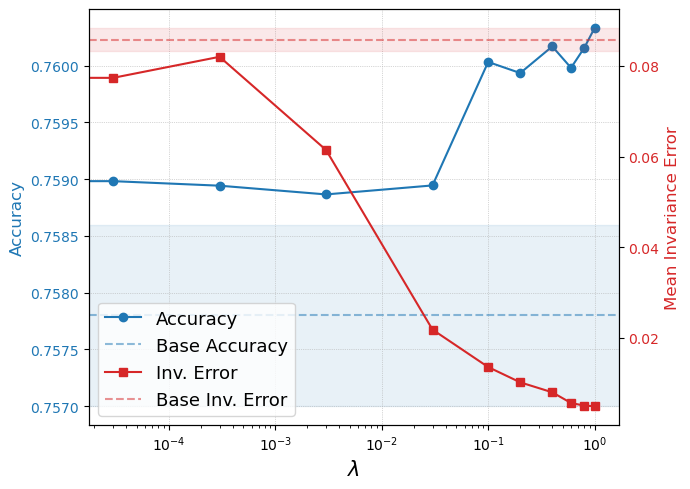

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import os
import yaml

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl'
os.chdir(new_directory)
print("✅ Current Working Directory:", os.getcwd())

model = "plot/transformer_px_py_pz_etarel_phirel_32_so2_eta_phi/lam_scan_so2_compare_to_output_nomask"
base_model = "plot_folds/transformer_px_py_pz_etarel_phirel_32/folds_report"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
inv_std = []
accs = []
acc_std = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc if isinstance(acc, float) else np.nan)

    acc_s = model_info.get("Validation Performance", {}).get("Test Accuracy Std", 0)
    acc_std.append(acc_s if isinstance(acc_s, float) else 0)

    inv = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv if isinstance(inv, float) else np.nan)

    inv_s = model_info.get("Invariance Properties", {}).get("Mean Invariance Error Std", 0)
    inv_std.append(inv_s if isinstance(inv_s, float) else 0)

lambda_list = np.array(lambda_list)
accs = np.array(accs)
acc_std = np.array(acc_std)
inv_errors = np.array(inv_errors)
inv_std = np.array(inv_std)

with open(f"{base_model}/model_info.yaml", "r") as f:
    base_model_info = yaml.safe_load(f)

base_acc_mean = float(base_model_info["Validation Performance"]["Test Accuracy"]["Mean"])
base_acc_std = float(base_model_info["Validation Performance"]["Test Accuracy"]["Std"])
base_inv_error_mean = float(base_model_info["Invariance Properties"]["Mean Invariance Error"]["Mean"])
base_inv_error_std = float(base_model_info["Invariance Properties"]["Mean Invariance Error"]["Std"])


fig, ax_main = plt.subplots(figsize=(7, 5))

#ax_main.set_title('Accuracy and Invariance Error vs Lambda')
ax_main.set_xlabel(r'$\lambda$', fontsize=15)
ax_main.set_ylabel('Accuracy', color='tab:blue', fontsize=12)

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red', fontsize=12)

ax_main.set_xscale('log')

# Accuracy line and fill
line_acc, = ax_main.plot(lambda_list, accs, marker='o', color='tab:blue', label='Accuracy')

# Base accuracy shaded band
line_base_acc = ax_main.axhline(y=base_acc_mean, linestyle='--', color='tab:blue', alpha=0.5, label='Base Accuracy')
ax_main.axhspan(base_acc_mean - base_acc_std, base_acc_mean + base_acc_std, color='tab:blue', alpha=0.1)

ax_main.tick_params(axis='y', labelcolor='tab:blue')

# Invariance error line and fill
line_inv, = ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red', label='Inv. Error')

# Base inv error shaded band
line_base_inv = ax2_main.axhline(y=base_inv_error_mean, linestyle='--', color='tab:red', alpha=0.5, label='Base Inv. Error')
ax2_main.axhspan(base_inv_error_mean - base_inv_error_std, base_inv_error_mean + base_inv_error_std, color='tab:red', alpha=0.1)

ax2_main.tick_params(axis='y', labelcolor='tab:red')

# Combine legends
lines = [line_acc, line_base_acc, line_inv, line_base_inv]
labels = [line.get_label() for line in lines]
ax_main.legend(lines, labels, loc='lower left', frameon=True, fontsize=13)

ax_main.grid(True, linestyle=':', linewidth=0.5)
fig.tight_layout()
plt.show()


✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


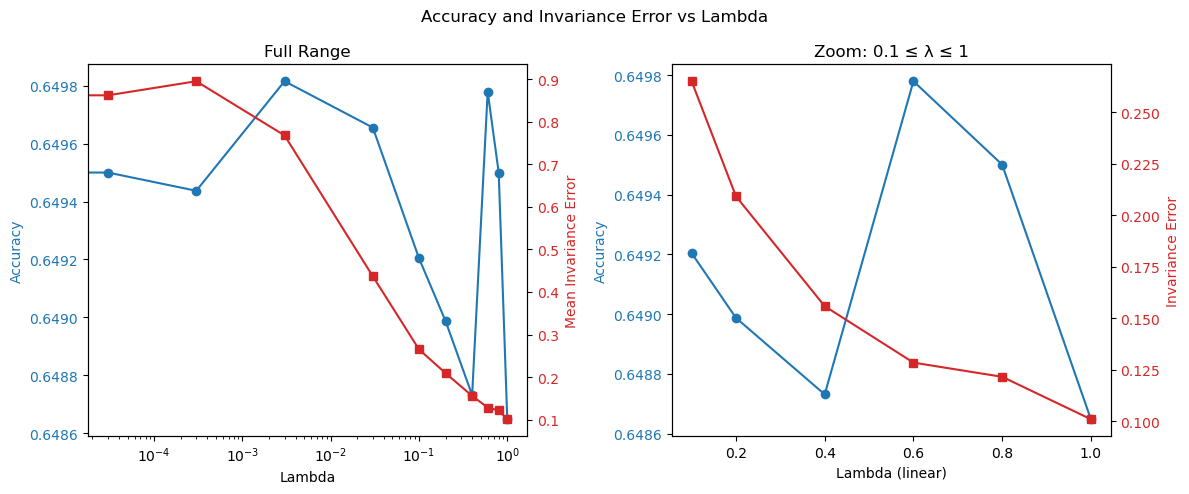

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

model = "transformer_px_py_pz_etarel_phirel_8_so2_eta_phi/lam_scan_so2"
base_model = "transformer_px_py_pz_etarel_phirel_8_data
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
accs = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    # Extracting relevant data
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc)
    
    inv_error = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv_error)
    
lambda_list = np.array(lambda_list)
accs = np.array(accs)
inv_errors = np.array(inv_errors)

mask_zoom = (lambda_list >= 0.1) & (lambda_list <= 1)
lambda_zoom = lambda_list[mask_zoom]
accs_zoom = accs[mask_zoom]
inv_zoom = inv_errors[mask_zoom]

# Create horizontal subplots
fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# --- Main plot (log scale) ---
ax_main.set_title('Full Range')
ax_main.set_xlabel('Lambda')
ax_main.set_ylabel('Accuracy', color='tab:blue')
ax_main.plot(lambda_list, accs, marker='o', color='tab:blue')
ax_main.tick_params(axis='y', labelcolor='tab:blue')
ax_main.set_xscale('log')

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red')
ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red')
ax2_main.tick_params(axis='y', labelcolor='tab:red')

# --- Zoomed plot (linear scale) ---
ax_zoom.set_title('Zoom: 0.1 ≤ λ ≤ 1')
ax_zoom.set_xlabel('Lambda (linear)')
ax_zoom.set_ylabel('Accuracy', color='tab:blue')
ax_zoom.plot(lambda_zoom, accs_zoom, marker='o', color='tab:blue')
ax_zoom.tick_params(axis='y', labelcolor='tab:blue')

ax2_zoom = ax_zoom.twinx()
ax2_zoom.set_ylabel('Invariance Error', color='tab:red')
ax2_zoom.plot(lambda_zoom, inv_zoom, marker='s', color='tab:red')
ax2_zoom.tick_params(axis='y', labelcolor='tab:red')

fig.suptitle('Accuracy and Invariance Error vs Lambda')
fig.tight_layout()
plt.show()

✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


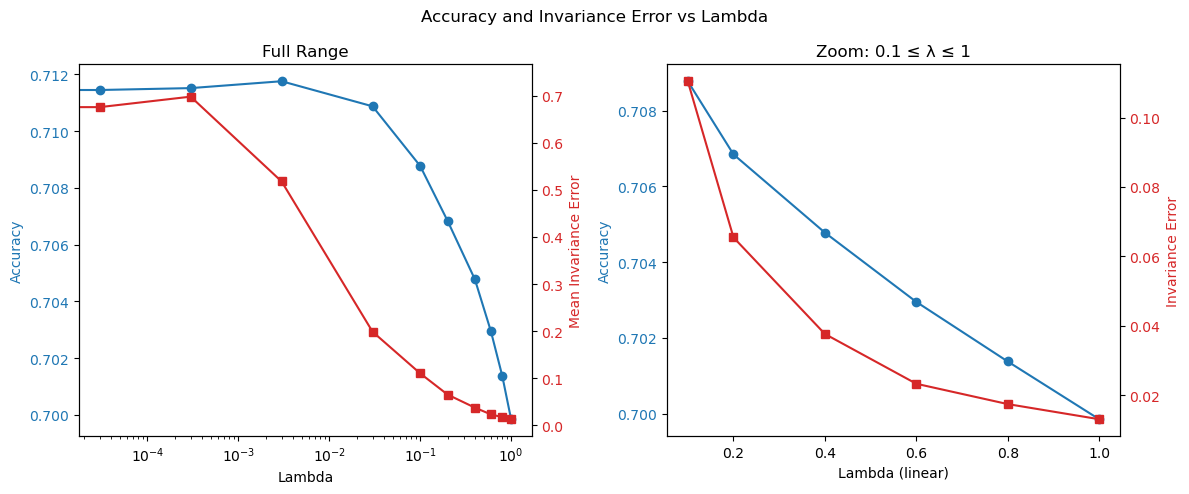

In [20]:
import numpy as np 
import matplotlib.pyplot as plt

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

model = "transformer_px_py_pz_etarel_phirel_16_so3_eta_phi/lam_scan"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
accs = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    # Extracting relevant data
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc)
    
    inv_error = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv_error)
    
lambda_list = np.array(lambda_list)
accs = np.array(accs)
inv_errors = np.array(inv_errors)

mask_zoom = (lambda_list >= 0.1) & (lambda_list <= 1)
lambda_zoom = lambda_list[mask_zoom]
accs_zoom = accs[mask_zoom]
inv_zoom = inv_errors[mask_zoom]

# Create horizontal subplots
fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# --- Main plot (log scale) ---
ax_main.set_title('Full Range')
ax_main.set_xlabel('Lambda')
ax_main.set_ylabel('Accuracy', color='tab:blue')
ax_main.plot(lambda_list, accs, marker='o', color='tab:blue')
ax_main.tick_params(axis='y', labelcolor='tab:blue')
ax_main.set_xscale('log')

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red')
ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red')
ax2_main.tick_params(axis='y', labelcolor='tab:red')

# --- Zoomed plot (linear scale) ---
ax_zoom.set_title('Zoom: 0.1 ≤ λ ≤ 1')
ax_zoom.set_xlabel('Lambda (linear)')
ax_zoom.set_ylabel('Accuracy', color='tab:blue')
ax_zoom.plot(lambda_zoom, accs_zoom, marker='o', color='tab:blue')
ax_zoom.tick_params(axis='y', labelcolor='tab:blue')

ax2_zoom = ax_zoom.twinx()
ax2_zoom.set_ylabel('Invariance Error', color='tab:red')
ax2_zoom.plot(lambda_zoom, inv_zoom, marker='s', color='tab:red')
ax2_zoom.tick_params(axis='y', labelcolor='tab:red')

fig.suptitle('Accuracy and Invariance Error vs Lambda')
fig.tight_layout()
plt.show()

✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


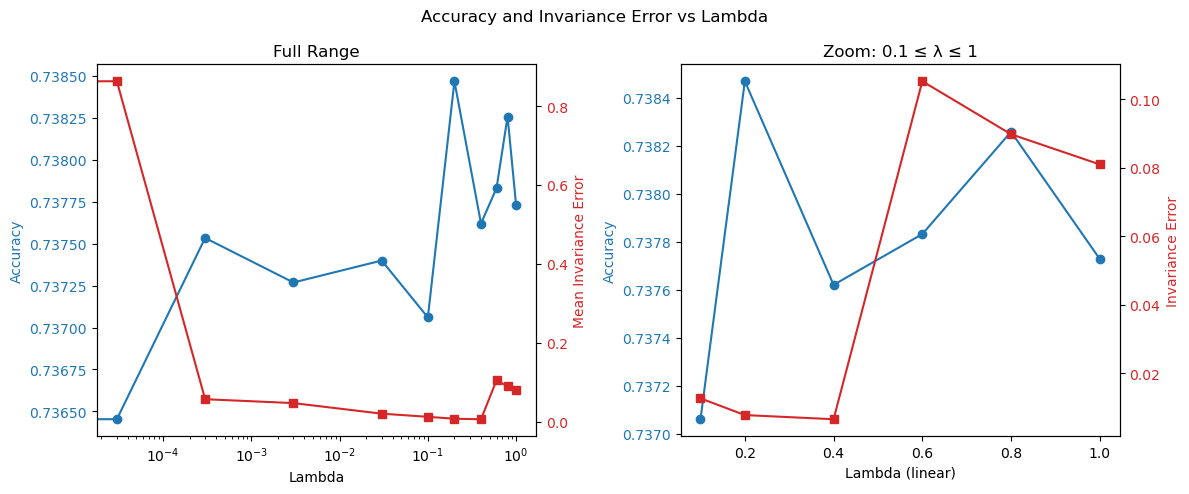

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'

# Change the working directory
os.chdir(new_directory)

# Verify the change
print("✅ Current Working Directory:", os.getcwd())

model = "transformer_px_py_pz_etarel_phirel_32_so2_eta_phi/lam_scan_so2"
base_model = "transformer_px_py_pz_etarel_phirel_32_data_aug/base_performance"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
accs = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    
    # Extracting relevant data
    acc = model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
    accs.append(acc)
    
    inv_error = model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")
    inv_errors.append(inv_error)
    
lambda_list = np.array(lambda_list)
accs = np.array(accs)
inv_errors = np.array(inv_errors)

file_name = f"{base_model}/model_info.yaml"
with open(file_name, "r") as f:
    base_model_info = yaml.safe_load(f)
    
base_acc = base_model_info.get("Validation Performance", {}).get("Test Accuracy", "N/A")
base_inv_error = base_model_info.get("Invariance Properties", {}).get("Mean Invariance Error", "N/A")

mask_zoom = (lambda_list >= 0.1) & (lambda_list <= 1)
lambda_zoom = lambda_list[mask_zoom]
accs_zoom = accs[mask_zoom]
inv_zoom = inv_errors[mask_zoom]

# Create horizontal subplots
fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# --- Main plot (log scale) ---
ax_main.set_title('Full Range')
ax_main.set_xlabel('Lambda')
ax_main.set_ylabel('Accuracy', color='tab:blue')
ax_main.plot(lambda_list, accs, marker='o', color='tab:blue')
ax_main.tick_params(axis='y', labelcolor='tab:blue')
ax_main.set_xscale('log')

ax2_main = ax_main.twinx()
ax2_main.set_ylabel('Mean Invariance Error', color='tab:red')
ax2_main.plot(lambda_list, inv_errors, marker='s', color='tab:red')
ax2_main.tick_params(axis='y', labelcolor='tab:red')

# --- Zoomed plot (linear scale) ---
ax_zoom.set_title('Zoom: 0.1 ≤ λ ≤ 1')
ax_zoom.set_xlabel('Lambda (linear)')
ax_zoom.set_ylabel('Accuracy', color='tab:blue')
ax_zoom.plot(lambda_zoom, accs_zoom, marker='o', color='tab:blue')
ax_zoom.tick_params(axis='y', labelcolor='tab:blue')

ax2_zoom = ax_zoom.twinx()
ax2_zoom.set_ylabel('Invariance Error', color='tab:red')
ax2_zoom.plot(lambda_zoom, inv_zoom, marker='s', color='tab:red')
ax2_zoom.tick_params(axis='y', labelcolor='tab:red')

fig.suptitle('Accuracy and Invariance Error vs Lambda')
fig.tight_layout()
plt.show()

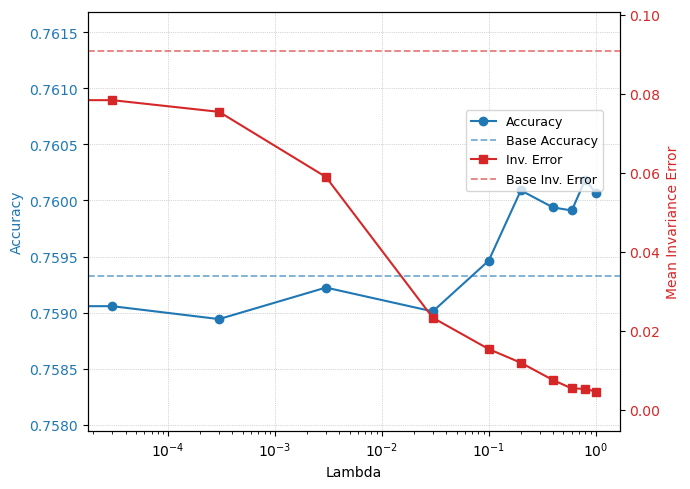

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import os
import yaml

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'
os.chdir(new_directory)

model = "transformer_px_py_pz_etarel_phirel_32_so2_eta_phi/lam_scan_so2_compare_to_output"
base_model = "transformer_px_py_pz_etarel_phirel_32/base_performance"
lambda_list = [0, 3e-5, 3e-4, 3e-3, 3e-2, 1e-1, 2e-1, 4e-1, 6e-1, 8e-1, 1]

inv_errors = []
accs = []

for lambd in lambda_list:
    file_name = f"{model}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)

    acc = model_info["Validation Performance"]["Test Accuracy"]
    inv_error = model_info["Invariance Properties"]["Mean Invariance Error"]

    accs.append(acc)
    inv_errors.append(inv_error)

lambda_list = np.array(lambda_list)
accs = np.array(accs)
inv_errors = np.array(inv_errors)

with open(f"{base_model}/model_info.yaml", "r") as f:
    base_model_info = yaml.safe_load(f)

base_acc = base_model_info["Validation Performance"]["Test Accuracy"]
base_inv_error = base_model_info["Invariance Properties"]["Mean Invariance Error"]

# Plot setup
fig, ax1 = plt.subplots(figsize=(7, 5))

ax1.set_xlabel('Lambda')
ax1.set_xscale('log')

# Accuracy
ax1.set_ylabel('Accuracy', color='tab:blue')
line_acc, = ax1.plot(lambda_list, accs, 'o-', color='tab:blue', label='Accuracy')
base_acc_line = ax1.axhline(y=base_acc, linestyle='--', linewidth=1.3,
                            color='tab:blue', alpha=0.6, label='Base Accuracy')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Invariance Error
ax2 = ax1.twinx()
ax2.set_ylabel('Mean Invariance Error', color='tab:red')
line_inv, = ax2.plot(lambda_list, inv_errors, 's-', color='tab:red', label='Inv. Error')
base_inv_line = ax2.axhline(y=base_inv_error, linestyle='--', linewidth=1.3,
                            color='tab:red', alpha=0.6, label='Base Inv. Error')
ax2.tick_params(axis='y', labelcolor='tab:red')

# === Smart axis limits ===
acc_min, acc_max = min(accs), max(accs)
# Include base_acc and space around it
acc_ymin = min(acc_min, base_acc) - 0.001
acc_ymax = max(acc_max, base_acc) + 0.0015
ax1.set_ylim(acc_ymin, acc_ymax)

inv_min, inv_max = min(inv_errors), max(inv_errors)
inv_ymin = min(inv_min, base_inv_error) - 0.01
inv_ymax = max(inv_max, base_inv_error) + 0.01
ax2.set_ylim(inv_ymin, inv_ymax)

# Legend
handles = [line_acc, base_acc_line, line_inv, base_inv_line]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.98, 0.78), frameon=True, fontsize=9)

# Layout
ax1.grid(True, linestyle=':', linewidth=0.5)
fig.tight_layout()
plt.show()



✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


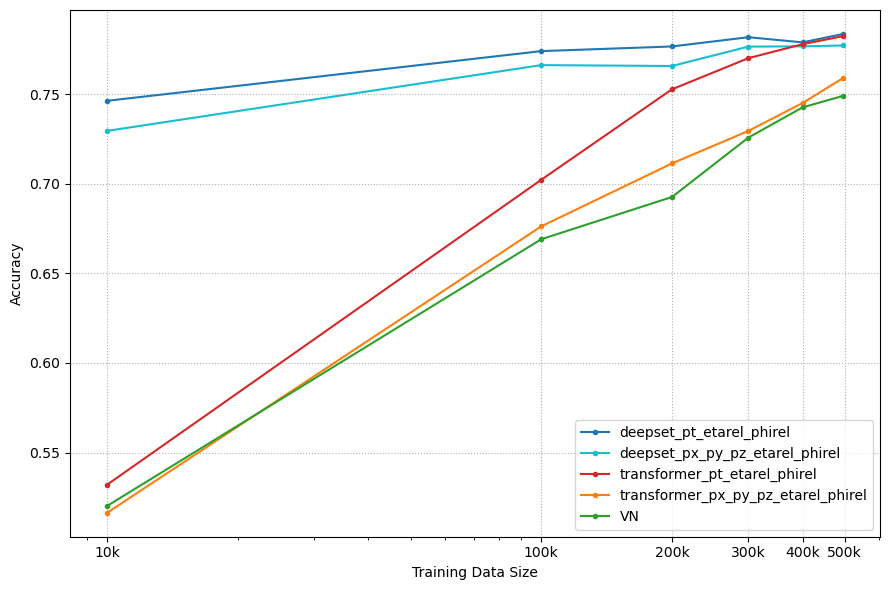

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt
import os
import yaml

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'
os.chdir(new_directory)
print("✅ Current Working Directory:", os.getcwd())

model_deep_pt = "deepset_pt_etarel_phirel_32/data_size_scan_2"
model_transformer_pt = "transformer_pt_etarel_phirel_32/data_size_scan_2"
model_deep_vec = "deepset_px_py_pz_etarel_phirel_32/data_size_scan_2"
model_transformer_vec = "transformer_px_py_pz_etarel_phirel_32/data_size_scan_2"

model_deep_aug = "deepset_px_py_pz_etarel_phirel_data_aug_32/data_size_scan_3"
model_transformer_aug = "transformer_px_py_pz_etarel_phirel_data_aug_32/data_size_scan_3"
model_deep_symm_loss = "deepset_px_py_pz_etarel_phirel_32_so2_eta_phi/data_size_scan"
model_transformer_symm_loss = "transformer_px_py_pz_etarel_phirel_32_so2_eta_phi/data_size_scan"

model_vn = "vector_neuron_so2_px_py_pz_jet_center_32/data_size_scan"


d_list = [1e4, 1e5, 2e5, 3e5, 4e5, 0]
accs = {
    "deepset_pt_etarel_phirel": [],
    "transformer_pt_etarel_phirel": [],
    "transformer_px_py_pz_etarel_phirel": [],
    "deepset_px_py_pz_etarel_phirel": [],
    "VN": []
}

for lambd in d_list:
    file_name = f"{model_deep_pt}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    accs["deepset_pt_etarel_phirel"].append(model_info["Validation Performance"]["Test Accuracy"])

    file_name = f"{model_transformer_pt}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    accs["transformer_pt_etarel_phirel"].append(model_info["Validation Performance"]["Test Accuracy"])

    file_name = f"{model_transformer_vec}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    accs["transformer_px_py_pz_etarel_phirel"].append(model_info["Validation Performance"]["Test Accuracy"])

    file_name = f"{model_deep_vec}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    accs["deepset_px_py_pz_etarel_phirel"].append(model_info["Validation Performance"]["Test Accuracy"])
    
    file_name = f"{model_vn}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    accs["VN"].append(model_info["Validation Performance"]["Test Accuracy"])

# Replace 0 with correct final value
d_list[-1] = 4.96e5
d_list = np.array(d_list)

# Plot

# Harmonized but distinct shades
color_map = {
    "deepset_pt_etarel_phirel": "#1f77b4",        # deep blue
    "deepset_px_py_pz_etarel_phirel": "#17becf",  # teal

    "transformer_pt_etarel_phirel": "#d62728",         # red
    "transformer_px_py_pz_etarel_phirel": "#ff7f0e",   # orange

    "VN": "#2ca02c"  # green
}

ordered_keys = [
    "deepset_pt_etarel_phirel",
    "deepset_px_py_pz_etarel_phirel",
    "transformer_pt_etarel_phirel",
    "transformer_px_py_pz_etarel_phirel",
    "VN"
]

plt.figure(figsize=(9, 6))
for model in ordered_keys:
    accs[model] = np.array(accs[model])
    plt.plot(d_list, accs[model], marker='.', label=model, color=color_map[model])

plt.xscale('log')
plt.xlabel('Training Data Size')
plt.ylabel('Accuracy')

custom_ticks = [1e4, 1e5, 2e5, 3e5, 4e5, 5e5]
plt.xticks(custom_ticks, [f'{int(x/1e3):.0f}k' for x in custom_ticks])

plt.legend()
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()



✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


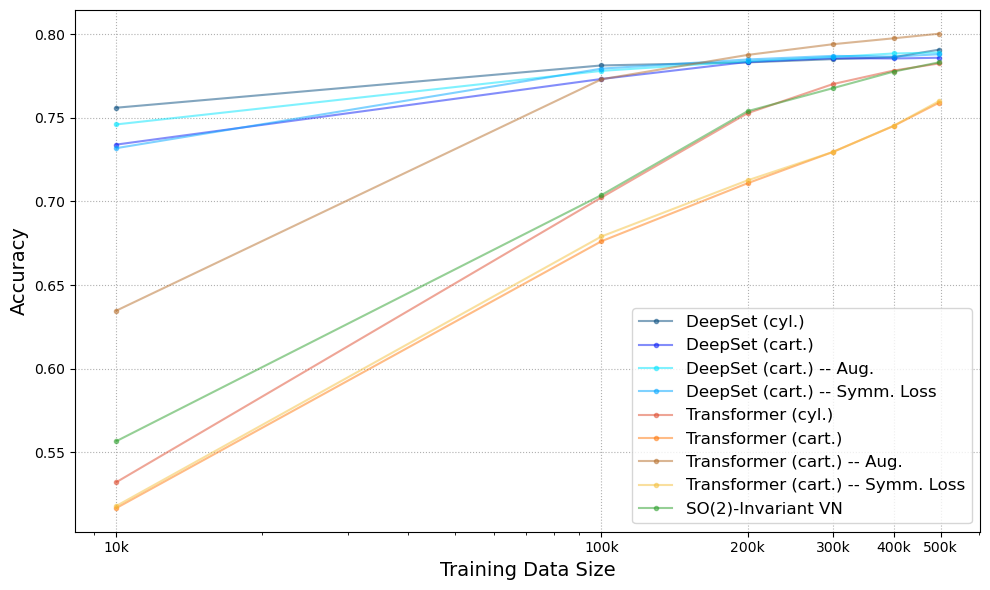

In [3]:
import numpy as np 
import matplotlib.pyplot as plt
import os
import yaml

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'
os.chdir(new_directory)
print("✅ Current Working Directory:", os.getcwd())

model_deep_pt = "deepset_pt_etarel_phirel_32/data_size_scan_2"
model_transformer_pt = "transformer_pt_etarel_phirel_32/data_size_scan_2"
model_deep_vec = "deepset_px_py_pz_etarel_phirel_32/data_size_scan_2"
model_transformer_vec = "transformer_px_py_pz_etarel_phirel_32/data_size_scan_2"

model_deep_aug = "deepset_px_py_pz_etarel_phirel_data_aug_32/data_size_scan_3"
model_transformer_aug = "transformer_px_py_pz_etarel_phirel_data_aug_32/data_size_scan_3"
model_deep_symm_loss = "deepset_px_py_pz_etarel_phirel_32_so2_eta_phi/data_size_scan"
model_transformer_symm_loss = "transformer_px_py_pz_etarel_phirel_32_so2_eta_phi/data_size_scan"

model_vn = "vector_neuron_so2_px_py_pz_jet_center_32/data_size_scan"

d_list = [1e4, 1e5, 2e5, 3e5, 4e5, 0]
accs = {
    "deepset_pt_etarel_phirel": [],
    "deepset_px_py_pz_etarel_phirel": [],
    "transformer_pt_etarel_phirel": [],
    "transformer_px_py_pz_etarel_phirel": [],
    "deepset_augmented": [],
    "transformer_augmented": [],
    "deepset_symmloss": [],
    "transformer_symmloss": [],
    "VN": []
}

# Updated loop
for lambd in d_list:
    def read_acc(path):  # helper to keep it clean
        with open(f"{path}/{lambd}/model_info.yaml", "r") as f:
            return yaml.safe_load(f)["Validation Performance"]["Test Accuracy"]

    accs["deepset_pt_etarel_phirel"].append(read_acc(model_deep_pt))
    accs["deepset_px_py_pz_etarel_phirel"].append(read_acc(model_deep_vec))
    accs["transformer_pt_etarel_phirel"].append(read_acc(model_transformer_pt))
    accs["transformer_px_py_pz_etarel_phirel"].append(read_acc(model_transformer_vec))
    accs["deepset_augmented"].append(read_acc(model_deep_aug))
    accs["transformer_augmented"].append(read_acc(model_transformer_aug))
    accs["deepset_symmloss"].append(read_acc(model_deep_symm_loss))
    accs["transformer_symmloss"].append(read_acc(model_transformer_symm_loss))
    accs["VN"].append(read_acc(model_vn))

# Fix final data size
d_list[-1] = 4.96e5
d_list = np.array(d_list)

# Updated color map
color_map = {
    "deepset_pt_etarel_phirel": "#064c7ffd",
    "deepset_px_py_pz_etarel_phirel": "#091df6",
    "deepset_augmented": "#03e5fe",
    "deepset_symmloss": "#00a6ff",

    "transformer_pt_etarel_phirel": "#df4c2f",
    "transformer_px_py_pz_etarel_phirel": "#ff7a0e",
    "transformer_augmented": "#b76e2a",
    "transformer_symmloss": "#f5c13e",

    "VN": "#2ca02c"
}

# Ordered keys for plotting
ordered_keys = [
    "deepset_pt_etarel_phirel",
    "deepset_px_py_pz_etarel_phirel",
    "deepset_augmented",
    "deepset_symmloss",
    "transformer_pt_etarel_phirel",
    "transformer_px_py_pz_etarel_phirel",
    "transformer_augmented",
    "transformer_symmloss",
    "VN"
]

label_map = {
    "deepset_pt_etarel_phirel": r"DeepSet ($p_T$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$)",
    "deepset_px_py_pz_etarel_phirel": r"DeepSet ($p_x$, $p_y$, $p_z$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$)",
    "deepset_augmented": r"DeepSet ($p_x$, $p_y$, $p_z$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$) -- Aug.",
    "deepset_symmloss": r"DeepSet ($p_x$, $p_y$, $p_z$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$) -- Symm. Loss",

    "transformer_pt_etarel_phirel": r"Transformer ($p_T$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$)",
    "transformer_px_py_pz_etarel_phirel": r"Transformer ($p_x$, $p_y$, $p_z$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$)",
    "transformer_augmented": r"Transformer ($p_x$, $p_y$, $p_z$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$) -- Aug.",
    "transformer_symmloss": r"Transformer ($p_x$, $p_y$, $p_z$, $\eta_{\mathrm{rel}}$, $\phi_{\mathrm{rel}}$) -- Symm. Loss",

    "VN": r"SO(2)-Invariant VN"
}

label_map = {
    "deepset_pt_etarel_phirel": r"DeepSet (cyl.)",
    "deepset_px_py_pz_etarel_phirel": r"DeepSet (cart.)",
    "deepset_augmented": r"DeepSet (cart.) -- Aug.",
    "deepset_symmloss": r"DeepSet (cart.) -- Symm. Loss",

    "transformer_pt_etarel_phirel": r"Transformer (cyl.)",
    "transformer_px_py_pz_etarel_phirel": r"Transformer (cart.)",
    "transformer_augmented": r"Transformer (cart.) -- Aug.",
    "transformer_symmloss": r"Transformer (cart.) -- Symm. Loss",

    "VN": r"SO(2)-Invariant VN"
}


# Plot
plt.figure(figsize=(10, 6))
for model in ordered_keys:
    accs[model] = np.array(accs[model])
    plt.plot(d_list, accs[model], marker='.', label=label_map[model], color=color_map[model], alpha=0.5)


plt.xscale('log')
plt.xlabel('Training Data Size', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)

custom_ticks = [1e4, 1e5, 2e5, 3e5, 4e5, 5e5]
plt.xticks(custom_ticks, [f'{int(x/1e3):.0f}k' for x in custom_ticks])

plt.legend(loc='lower right', fontsize=12)
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()


✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot_folds


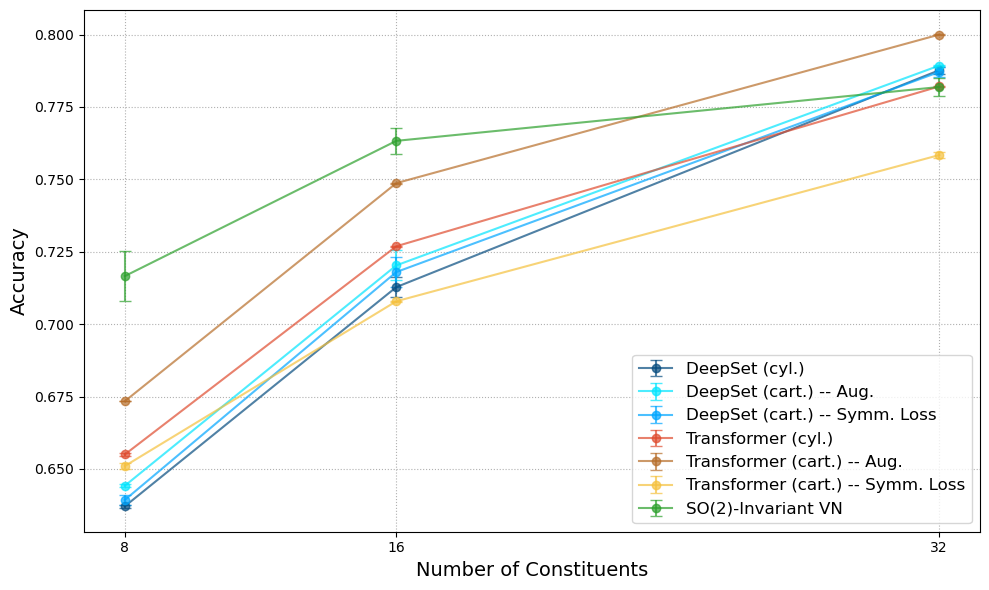

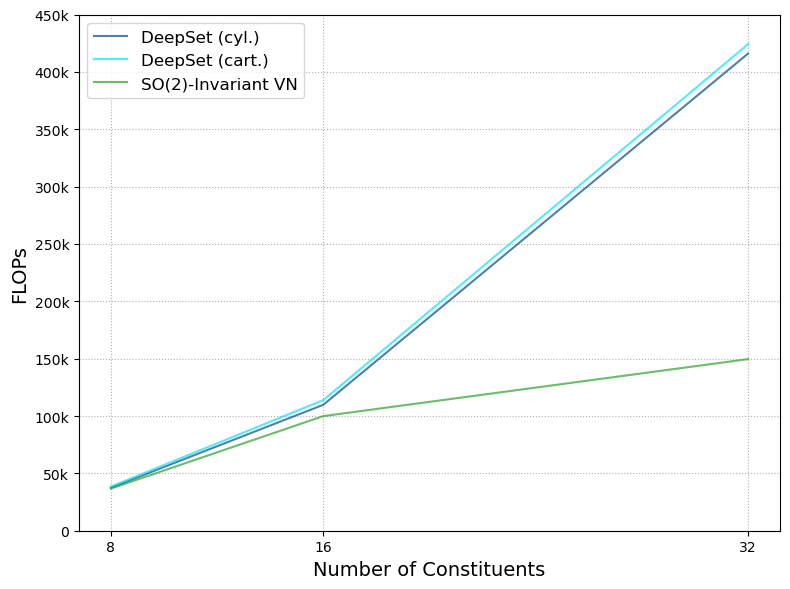

In [24]:
import numpy as np 
import matplotlib.pyplot as plt
import os
import yaml

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot_folds'
os.chdir(new_directory)
print("✅ Current Working Directory:", os.getcwd())

ordered_keys = [
    "deepset_pt_etarel_phirel",
    "deepset_augmented",
    "deepset_symmloss",
    "transformer_pt_etarel_phirel",
    "transformer_augmented",
    "transformer_symmloss",
    "VN"
]

label_map = {
    "deepset_pt_etarel_phirel": r"DeepSet (cyl.)",
    "deepset_augmented": r"DeepSet (cart.) -- Aug.",
    "deepset_symmloss": r"DeepSet (cart.) -- Symm. Loss",

    "transformer_pt_etarel_phirel": r"Transformer (cyl.)",
    "transformer_augmented": r"Transformer (cart.) -- Aug.",
    "transformer_symmloss": r"Transformer (cart.) -- Symm. Loss",

    "VN": r"SO(2)-Invariant VN"
}

color_map = {
    "deepset_pt_etarel_phirel": "#064c7ffd",
    "deepset_augmented": "#03e5fe",
    "deepset_symmloss": "#00a6ff",

    "transformer_pt_etarel_phirel": "#df4c2f",
    "transformer_augmented": "#b76e2a",
    "transformer_symmloss": "#f5c13e",

    "VN": "#2ca02c"
}

constituents = [8, 16, 32]

base_paths = {
    "deepset_pt_etarel_phirel": "deepset_pt_etarel_phirel_{}/folds_report",
    "deepset_augmented": "deepset_px_py_pz_etarel_phirel_data_aug_{}/folds_report",
    "deepset_symmloss": "deepset_px_py_pz_etarel_phirel_{}_so2_eta_phi/folds_report",

    "transformer_pt_etarel_phirel": "transformer_pt_etarel_phirel_{}/folds_report",
    "transformer_augmented": "transformer_px_py_pz_etarel_phirel_data_aug_{}/folds_report",
    "transformer_symmloss": "transformer_px_py_pz_etarel_phirel_{}_so2_eta_phi/folds_report",

    "VN": "vector_neuron_so2_px_py_pz_jet_center_{}/so2_inv"
}

accs = {k: [] for k in base_paths}
stds = {k: [] for k in base_paths}
flops = {k: [] for k in base_paths}

def read_acc(path):
    with open(f"{path}/model_info.yaml", "r") as f:
        return float(yaml.safe_load(f)["Validation Performance"]["Test Accuracy"]["Mean"])
    
def read_std(path):
    with open(f"{path}/model_info.yaml", "r") as f:
        return float(yaml.safe_load(f)["Validation Performance"]["Test Accuracy"]["Std"])
    
def read_flops(path):
    with open(f"{path}/model_info.yaml", "r") as f:
        return float(yaml.safe_load(f)["Model Specifications"]["FLOPs"]["Mean"])
    
manual_flops_map = {
    "transformer_pt_etarel_phirel":     {8: 37937152.0, 16: 76136448.0, 32: 153321472.0},
    "transformer_augmented":            {8: 37941248.0, 16: 76144640.0, 32: 153337856.0},
}


for const in constituents:
    for model_key, path_template in base_paths.items():
        full_path = path_template.format(const)

        accs[model_key].append(read_acc(full_path))
        stds[model_key].append(read_std(full_path))

        if model_key in manual_flops_map and const in manual_flops_map[model_key]:
            flops[model_key].append(manual_flops_map[model_key][const])
        else:
            flops[model_key].append(read_flops(full_path))


# Plotting with error bars
plt.figure(figsize=(10, 6))
for model in ordered_keys:
    acc_array = np.array(accs[model])
    std_array = np.array(stds[model])
    plt.errorbar(
        constituents,
        acc_array,
        yerr=std_array,
        fmt='o-',
        label=label_map[model],
        color=color_map[model],
        alpha=0.7,
        capsize=4  # little caps on error bars
    )

plt.xticks(constituents, [f'{c}' for c in constituents])
plt.xlabel('Number of Constituents', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.grid(True, linestyle=':')
plt.legend(loc='lower right', fontsize=12)
plt.tight_layout()
plt.show()

###########################################################################################

# Define merge logic to avoid redundant FLOP plots
flops_merge_map = {
    "deepset_augmented": "deepset_cartesian_base",
    "deepset_symmloss": "deepset_cartesian_base"
}

# Assign base FLOP data from one representative variant
flops["deepset_cartesian_base"] = flops["deepset_augmented"]

# Label and color for merged base models
label_map["deepset_cartesian_base"] = r"DeepSet (cart.)"
color_map["deepset_cartesian_base"] = "#03e5fe"

# Define which models to plot
deepset_vn_keys = [
    "deepset_pt_etarel_phirel",
    "deepset_cartesian_base",
    "VN"
]

# Plot
plt.figure(figsize=(8, 6))
already_plotted = set()

for model in deepset_vn_keys:
    if model in flops_merge_map:
        base_model = flops_merge_map[model]
        if base_model in already_plotted:
            continue
        model = base_model

    flops_array = np.array(flops[model])
    plt.plot(
        constituents,
        flops_array,
        label=label_map[model],
        color=color_map[model],
        alpha=0.7
    )
    already_plotted.add(model)

#plt.yscale('log')
yticks = plt.yticks()[0]  # Get current tick positions
ytick_labels = [f"{int(y/1e3)}k" if y >= 1e3 else f"{int(y)}" for y in yticks]
plt.yticks(yticks, ytick_labels)
plt.xticks(constituents, [f'{c}' for c in constituents])
plt.xlabel('Number of Constituents', fontsize=14)
plt.ylabel('FLOPs', fontsize=14)
plt.grid(True, linestyle=':')
plt.legend(loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()


✅ Current Working Directory: c:\Users\ZenBook\Desktop\semester_project_spring25\jet_tagging_gdl\plot


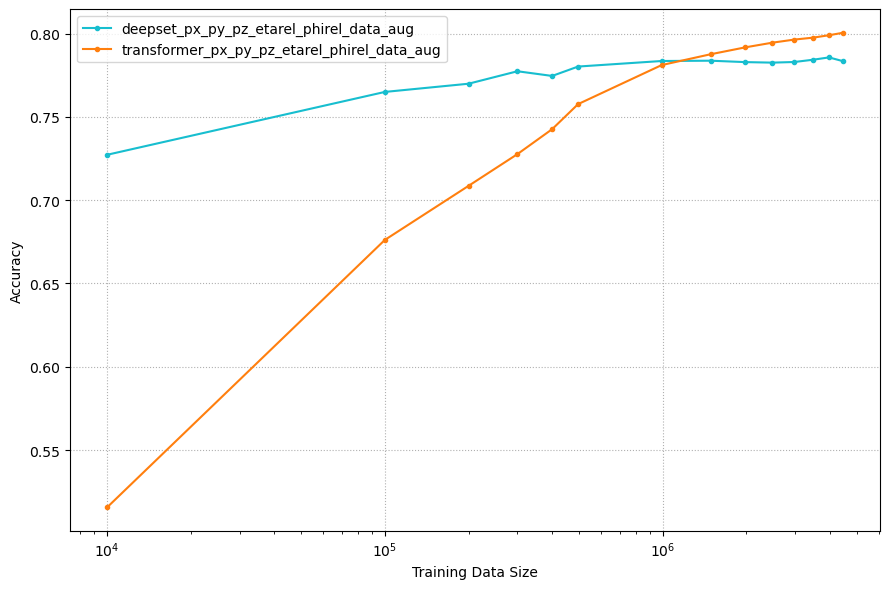

In [5]:
import numpy as np 
import matplotlib.pyplot as plt
import os
import yaml

new_directory = f'/Users/ZenBook/Desktop/semester_project_spring25/jet_tagging_gdl/plot'
os.chdir(new_directory)
print("✅ Current Working Directory:", os.getcwd())


model_deep_vec = "deepset_px_py_pz_etarel_phirel_data_aug_32/data_size_scan"
model_transformer_vec = "transformer_px_py_pz_etarel_phirel_data_aug_32/data_size_scan"

d_list = [1e4, 1e5, 2e5, 3e5, 4e5, 4.96e5, 2*4.96e5, 3*4.96e5, 4*4.96e5, 5*4.96e5, 6*4.96e5, 7*4.96e5, 8*4.96e5, 9*4.96e5]
accs = {
    "deepset_px_py_pz_etarel_phirel_data_aug": [],
    "transformer_px_py_pz_etarel_phirel_data_aug": [],
}

for lambd in d_list:

    file_name = f"{model_transformer_vec}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    accs["transformer_px_py_pz_etarel_phirel_data_aug"].append(model_info["Validation Performance"]["Test Accuracy"])

    file_name = f"{model_deep_vec}/{lambd}"
    with open(f"{file_name}/model_info.yaml", "r") as f:
        model_info = yaml.safe_load(f)
    accs["deepset_px_py_pz_etarel_phirel_data_aug"].append(model_info["Validation Performance"]["Test Accuracy"])
    

d_list = np.array(d_list)

# Plot

# Harmonized but distinct shades
color_map = {
    "deepset_px_py_pz_etarel_phirel_data_aug": "#17becf",  # teal

    "transformer_px_py_pz_etarel_phirel_data_aug": "#ff7f0e",   # orange

}

ordered_keys = [
    
    "deepset_px_py_pz_etarel_phirel_data_aug",
    "transformer_px_py_pz_etarel_phirel_data_aug",
    
]

plt.figure(figsize=(9, 6))
for model in ordered_keys:
    accs[model] = np.array(accs[model])
    plt.plot(d_list, accs[model], marker='.', label=model, color=color_map[model])

plt.xscale('log')
plt.xlabel('Training Data Size')
plt.ylabel('Accuracy')

# custom_ticks = [1e4, 1e5, 2e5, 3e5, 4e5, 5e5]
# plt.xticks(custom_ticks, [f'{int(x/1e3):.0f}k' for x in custom_ticks])

plt.legend()
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()